# Holding Still
### How rare is a slow shutter?

Most of my photographs are taken at about a tenth of a second, which is long enough for anything that moves to blur. This notebook measures how unusual that is. It uses the shutter speeds stored inside photographs on Wikimedia Commons, a public archive of freely licensed images, and compares them with twelve of my own photographs.

A Python script, `scripts/collect_commons.py`, asked the Commons API for files at random and kept the ones whose camera data (EXIF) recorded both the date the photograph was taken and its shutter speed. It never downloaded the images themselves. `scripts/build.py` cleans that data and builds the published page, and this notebook walks through the same steps so that each decision can be checked.

Everything here runs from three files in `data/processed/`. `commons_all.csv` holds every plausible record before the per-author limit described in section 5, `commons_clean.csv` holds the final sample, and `alex_photos.csv` holds my twelve photographs.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "scripts"))

# The notebook uses the same rules as the published page, imported from build.py
# rather than copied, so the two can't drift apart.
from build import LADDER, MAX_PER_AUTHOR, SEED, SLOW_S, is_mobile, on_ladder

SLOW = SLOW_S * 0.97          # 1/13 s, with room for files that write it as 0.0769
COLORS = {"camera": "#b8893a", "phone": "#4f8fd6", "alex": "#c062a8", "grey": "#9a9a9a"}

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

def speed(s):
    """Shutter speed as photographers write it: 1/200 s, 1/2 s, 4 s."""
    return f"1/{round(1 / s)} s" if s < 1 else f"{s:g} s"

def pct(x, places=1):
    return f"{100 * x:.{places}f}%"

## 2. Load the data

In [2]:
everything = pd.read_csv(DATA / "commons_all.csv", parse_dates=["captured"], keep_default_na=False)
sample = pd.read_csv(DATA / "commons_clean.csv", parse_dates=["captured"], keep_default_na=False)
alex = pd.read_csv(DATA / "alex_photos.csv")

for frame in (everything, sample):
    frame["year"] = frame["captured"].dt.year
    frame["slow"] = frame["exposure_s"] >= SLOW
sample["mobile"] = sample["mobile"].astype(str) == "True"
sample["ladder"] = sample["ladder"].astype(str) == "True"

print(f"Every plausible record:   {len(everything):>7,}")
print(f"Final sample:             {len(sample):>7,}  from {sample['artist'].str.strip().nunique():,} authors")
print(f"My photographs:           {len(alex):>7}")

Every plausible record:    59,945
Final sample:              49,335  from 20,076 authors
My photographs:                12


## 3. Data checks

Before any analysis I want to confirm three things: that each photograph appears only once, that every shutter speed is a sensible number, and that the dates fall inside the range the cleaning step allows. The cleaning counts come from the published page's data file, so they are the same numbers the page reports.

In [3]:
meta = json.loads((ROOT / "docs" / "data.json").read_text())["meta"]
steps = meta["cleaning"]

print("Duplicate files in the final sample:", sample["pageid"].duplicated().sum())
print("Shortest and longest exposure:      ", speed(sample["exposure_s"].min()), "and", speed(sample["exposure_s"].max()))
print("Earliest and latest capture year:   ", sample["year"].min(), "and", sample["year"].max())
print()
print(f"Photographs with a date and a shutter speed:   {steps['collected']:>7,}")
print(f"After removing implausible dates and speeds:   {steps['plausible_exposure']:>7,}")
print(f"After one photograph per author per day:       {steps['one_per_author_day']:>7,}")
print(f"After a limit of {MAX_PER_AUTHOR} photographs per author:     {steps['capped_per_author']:>7,}")

Duplicate files in the final sample: 0
Shortest and longest exposure:       1/1000000 s and 131 s
Earliest and latest capture year:    1999 and 2026

Photographs with a date and a shutter speed:    60,014
After removing implausible dates and speeds:    59,945
After one photograph per author per day:        54,226
After a limit of 50 photographs per author:      49,335


## 4. One archive tips the slow end

Commons receives uploads from individual photographers and also from institutions that upload in bulk. If one of those institutions shoots a lot of long exposures, it can make slow photography look far more common than it is. The table below lists the authors with the most photographs before any limit, along with how many of their photographs are slow.

In [4]:
by_author = (everything.groupby("author")
             .agg(photographs=("slow", "size"), slow=("slow", "sum"))
             .sort_values("photographs", ascending=False))
by_author["share of all slow photographs"] = (by_author["slow"] / everything["slow"].sum()).map(pct)
by_author.head(8)

,photographs,slow,share of all slow photographs
author,,,
"Earth Science and Remote Sensing Unit, Lyndon B. Johnson Space Center",3083,1107,33.4%
Judgefloro,1090,1,0.0%
"Earth Science and Remote Sensing Unit, NASA Johnson Space Center",737,198,6.0%
Chabe01,501,3,0.1%
,416,26,0.8%
"Martin Rulsch, Wikimedia Commons",387,0,0.0%
Sailko,213,9,0.3%
Sven Mandel,165,0,0.0%


In [5]:
nasa = everything["author"].str.contains("Johnson Space Center")
print(f"NASA's Earth Science and Remote Sensing Unit: {nasa.sum():,} photographs")
print(f"  share of all photographs:      {pct(nasa.mean())}")
print(f"  share of the slow photographs: {pct(everything.loc[nasa, 'slow'].sum() / everything['slow'].sum())}")

NASA's Earth Science and Remote Sensing Unit: 3,827 photographs
  share of all photographs:      6.4%
  share of the slow photographs: 39.4%


NASA's Earth Science and Remote Sensing Unit, which publishes astronaut photographs of Earth taken from the International Space Station, makes up about 6% of the records but close to 40% of the slow ones. Left in, it would make one archive the main story of the slow end. The next section limits how much any single author can contribute.

## 5. One photograph per author per day, and at most 50 per author

The rule keeps one photograph per author per day, which removes bursts and near-identical frames, and then caps every author at 50 photographs. The cap is a judgement call, so the second table checks whether the findings move when the cap changes or when the photographs are kept in a different random order.

In [6]:
def limit(df, cap, seed):
    shuffled = df.sample(frac=1, random_state=seed).assign(day=lambda d: d["captured"].dt.date)
    one_a_day = shuffled.drop_duplicates(["author", "day"])
    return one_a_day if cap is None else one_a_day.groupby("author", group_keys=False).head(cap)

def summarise(df):
    mobile = [is_mobile(a, b) for a, b in zip(df["make"], df["model"])]
    df = df.assign(mobile=mobile, ladder=df["exposure_s"].map(on_ladder))
    cams, phones = df[~df["mobile"]], df[df["mobile"]]
    return {
        "photographs": len(df),
        "slow": pct(df["slow"].mean()),
        "slow, cameras": pct(cams["slow"].mean()),
        "slow, phones": pct(phones["slow"].mean()),
        "on a dial speed, cameras": pct(cams["ladder"].mean()),
        "on a dial speed, phones": pct(phones["ladder"].mean()),
    }

check = limit(everything, MAX_PER_AUTHOR, SEED)
print("Photographs after the rule:", f"{len(check):,}", "(the published sample has", f"{len(sample):,})")

Photographs after the rule: 49,335 (the published sample has 49,335)


In [7]:
rows = {"no limit at all": summarise(everything)}
for cap in (None, 20, 50, 100):
    for seed in (1, 2, 3):
        label = f"one a day, {'no cap' if cap is None else f'cap {cap}'}, order {seed}"
        rows[label] = summarise(limit(everything, cap, seed))
pd.DataFrame(rows).T

,photographs,slow,"slow, cameras","slow, phones","on a dial speed, cameras","on a dial speed, phones"
no limit at all,59945,5.5%,6.3%,1.9%,92.8%,31.7%
"one a day, no cap, order 1",54226,4.2%,4.8%,1.9%,92.5%,31.8%
"one a day, no cap, order 2",54226,4.3%,4.8%,1.9%,92.5%,31.8%
"one a day, no cap, order 3",54226,4.3%,4.8%,1.9%,92.5%,31.9%
"one a day, cap 20, order 1",44615,3.8%,4.3%,1.9%,92.1%,32.8%
"one a day, cap 20, order 2",44615,3.8%,4.2%,2.0%,92.0%,32.7%
"one a day, cap 20, order 3",44615,3.8%,4.2%,1.9%,92.1%,32.8%
"one a day, cap 50, order 1",49335,3.8%,4.2%,1.9%,92.2%,32.5%
"one a day, cap 50, order 2",49335,3.8%,4.2%,1.9%,92.1%,32.4%
"one a day, cap 50, order 3",49335,3.8%,4.2%,2.0%,92.2%,32.6%


Without any limit, 5.5% of the photographs look slow, against 3.8% in the final sample, and almost all of that difference comes from the NASA uploads. Once each author is limited to one photograph a day, the cap of 20, 50 or 100 barely matters, and neither does the random order. The rest of the notebook uses the published sample, which applies a cap of 50.

## 6. Telling phones from cameras

The camera data records the maker and model of the device. A photograph counts as a phone or tablet when the maker is a phone company (Apple, Samsung, Google, Xiaomi, Sony Ericsson and others) or when the model name gives it away (iPhone, Galaxy, Pixel). Sony, Samsung and Kyocera made both, so their files count as phones only when the model name looks like a phone: an Xperia for Sony, and for Samsung a model code such as SM- or GT- or a Galaxy name rather than a Digimax, NX or WB camera. The tables show what ended up on each side, which is the quickest way to spot a mistake.

In [8]:
print(f"Phones and tablets: {sample['mobile'].sum():,} ({pct(sample['mobile'].mean())})")
print(f"Cameras:            {(~sample['mobile']).sum():,}")
makers = pd.concat({
    "cameras": sample.loc[~sample["mobile"], "make"].str.strip().value_counts().head(10).reset_index(),
    "phones": sample.loc[sample["mobile"], "make"].str.strip().value_counts().head(10).reset_index(),
}, axis=1)
makers

Phones and tablets: 8,991 (18.2%)
Cameras:            40,344


cameras           phones      
                    make  count      make count
0                  Canon  14509     Apple  2707
1      NIKON CORPORATION   8462   samsung  2447
2                   SONY   4786    Xiaomi   822
3              Panasonic   3611    HUAWEI   458
4                  NIKON   1705    Google   405
5               FUJIFILM   1574   SAMSUNG   326
6  OLYMPUS IMAGING CORP.   1192  motorola   240
7                           617     Nokia   201
8  EASTMAN KODAK COMPANY    494      Sony   121
9                SAMSUNG    361      OPPO   115

## 7. How long a photograph takes

In [9]:
e = sample["exposure_s"]
quantiles = pd.DataFrame({
    "share of photographs at this speed or faster": ["10%", "25%", "50% (median)", "75%", "90%", "99%"],
    "shutter speed": [speed(e.quantile(q)) for q in (0.10, 0.25, 0.50, 0.75, 0.90, 0.99)],
})
print(f"Photographs at {speed(SLOW_S)} or slower: {pct(sample['slow'].mean())}")
quantiles

Photographs at 1/13 s or slower: 3.8%


,share of photographs at this speed or faster,shutter speed
0,10%,1/1135 s
1,25%,1/500 s
2,50% (median),1/200 s
3,75%,1/80 s
4,90%,1/30 s
5,99%,1/3 s


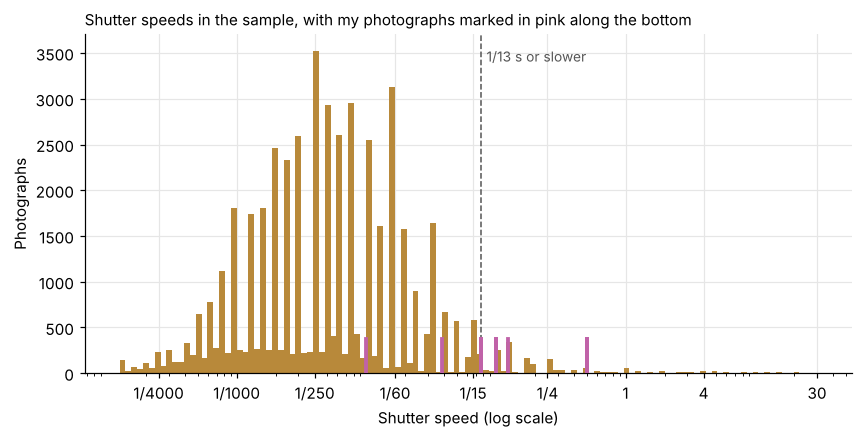

In [10]:
bins = np.logspace(np.log10(1 / 8000), np.log10(30), 120)
fig, ax = plt.subplots()
ax.hist(e.clip(1 / 8000, 30), bins=bins, color=COLORS["camera"])
ax.set_xscale("log")
ticks = [1/4000, 1/1000, 1/250, 1/60, 1/15, 1/4, 1, 4, 30]
ax.set_xticks(ticks, [speed(t).replace(" s", "") for t in ticks])
ax.axvline(SLOW_S, color="#555", linestyle="--", linewidth=1)
ax.text(SLOW_S * 1.1, ax.get_ylim()[1] * 0.92, "1/13 s or slower", fontsize=9, color="#555")
for s in alex["exposure_s"]:
    ax.axvline(s, ymax=0.1, color=COLORS["alex"], linewidth=2.5, zorder=5)
ax.set_xlabel("Shutter speed (log scale)")
ax.set_ylabel("Photographs")
ax.set_title("Shutter speeds in the sample, with my photographs marked in pink along the bottom", loc="left", fontsize=10)
plt.show()

The median photograph lasted 1/200 of a second and nine out of ten were 1/30 or faster. Only about 4% were as slow as 1/13 of a second, which is where most of my own work sits. The spikes in the histogram are the subject of the next section.

## 8. Cameras stay on the shutter dial

A shutter dial offers a fixed list of speeds in full and third stops, such as 1/60, 1/80, 1/100 and 1/125. An exposure counts as a dial speed here when it is within 1% of one of those values, from 1/8000 of a second to 30 seconds.

Camera exposures on a dial speed: 92.2%
Phone exposures on a dial speed:  32.4%


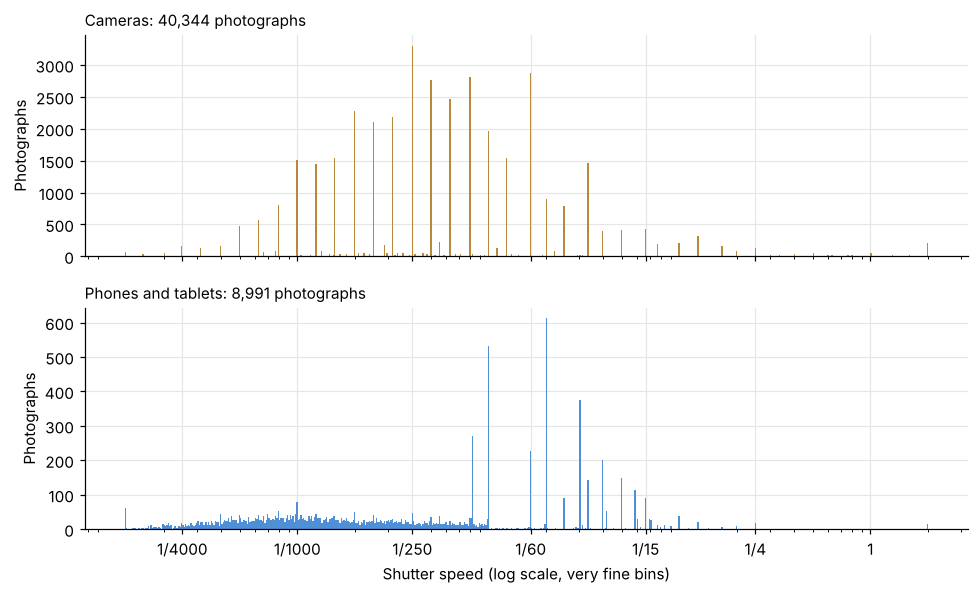

In [11]:
cams, phones = sample[~sample["mobile"]], sample[sample["mobile"]]
print(f"Camera exposures on a dial speed: {pct(cams['ladder'].mean())}")
print(f"Phone exposures on a dial speed:  {pct(phones['ladder'].mean())}")

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
fine = np.logspace(np.log10(1 / 8000), np.log10(2), 600)
for ax, group, name, color in ((axes[0], cams, "Cameras", COLORS["camera"]), (axes[1], phones, "Phones and tablets", COLORS["phone"])):
    ax.hist(group["exposure_s"].clip(1 / 8000, 2), bins=fine, color=color)
    ax.set_xscale("log")
    ax.set_title(f"{name}: {len(group):,} photographs", loc="left", fontsize=10)
    ax.set_ylabel("Photographs")
ticks = [1/4000, 1/1000, 1/250, 1/60, 1/15, 1/4, 1]
axes[1].set_xticks(ticks, [speed(t).replace(" s", "") for t in ticks])
axes[1].set_xlabel("Shutter speed (log scale, very fine bins)")
plt.tight_layout()
plt.show()

In [12]:
top = pd.concat({
    "cameras": cams["exposure_s"].round(6).value_counts().head(10).rename(index=speed).reset_index(),
    "phones": phones["exposure_s"].round(6).value_counts().head(10).rename(index=speed).reset_index(),
}, axis=1)
top

cameras           phones      
  exposure_s count exposure_s count
0    1/250 s  3301     1/50 s   499
1     1/60 s  2849    1/100 s   378
2    1/125 s  2798     1/33 s   237
3    1/200 s  2747     1/60 s   192
4    1/160 s  2465    1/120 s   172
5    1/500 s  2272     1/25 s   158
6    1/320 s  2180     1/30 s   131
7    1/400 s  2096     1/20 s   121
8    1/100 s  1957     1/17 s   108
9     1/80 s  1541     1/15 s    83

Camera exposures pile up on a short list of speeds, and the ten most common camera speeds are all standard dial values. Phone exposures spread across the values in between, because a phone chooses its own exposure in finer steps. Phones do have a few spikes of their own, the largest at 1/50 and 1/100 of a second. Those happen to match the flicker of mains lighting in countries with 50 Hz electricity, which pulses every 10 milliseconds, and several smaller spikes (1/33, 1/25, 1/20 and 1/17) are also whole multiples of that pulse. Phones often hold their exposure to whole flicker cycles to avoid banding, which is a likely reason for the spikes, although the camera data can't confirm it. Phones were also about half as likely as cameras to shoot at 1/13 of a second or slower.

## 9. Slow photographs have become rarer

Each point is the share of a year's photographs taken at 1/13 of a second or slower. A year is left out for a kind of device when the sample has fewer than 200 photographs from it, because the share would be too noisy to read.

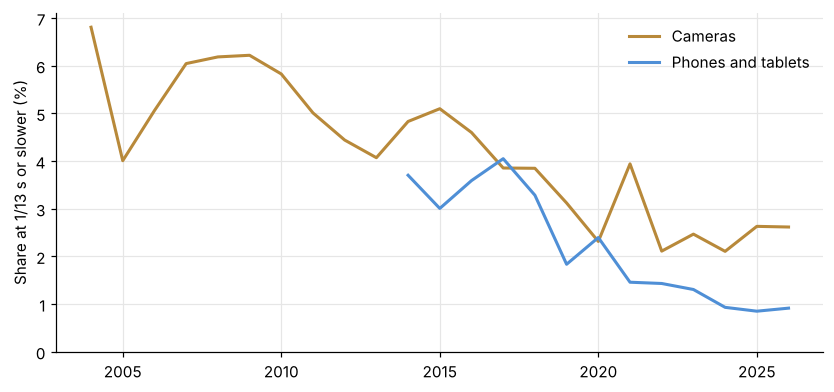

,photographs,"slow, all","slow, cameras","slow, phones",phones in the sample
2005–2012,"12,774",5.3%,5.4%,4.1%,2%
2013–2018,"17,292",4.3%,4.4%,3.5%,12%
2019–2026,"18,782",2.2%,2.7%,1.3%,35%


In [13]:
def yearly(group):
    g = group.groupby("year")["slow"].agg(["size", "mean"])
    return g[g["size"] >= 200]["mean"]

fig, ax = plt.subplots()
for group, name, color in ((cams, "Cameras", COLORS["camera"]), (phones, "Phones and tablets", COLORS["phone"])):
    series = yearly(group)
    ax.plot(series.index, series.values * 100, color=color, linewidth=2, label=name)
ax.set_ylabel("Share at 1/13 s or slower (%)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
plt.show()

periods = {}
for start, end in ((2005, 2012), (2013, 2018), (2019, 2026)):
    p = sample[sample["year"].between(start, end)]
    periods[f"{start}–{end}"] = {
        "photographs": f"{len(p):,}",
        "slow, all": pct(p["slow"].mean()),
        "slow, cameras": pct(p.loc[~p["mobile"], "slow"].mean()),
        "slow, phones": pct(p.loc[p["mobile"], "slow"].mean()),
        "phones in the sample": pct(p["mobile"].mean(), 0),
    }
pd.DataFrame(periods).T

Between 2005 and 2012, about 5% of the photographs in the sample were 1/13 of a second or slower, and between 2019 and 2026 the figure was about 2%. Phones grew from about 2% of the sample to 35% over the same period, which explains part of the drop, but cameras on their own also fell from about 5% to under 3%. The data can't say why cameras changed. Better sensors and stabilisation would push in that direction, and so would a changing idea of what a good photograph looks like.

## 10. Where my photographs sit

For each of my photographs, this is the share of the sample with a strictly faster shutter. The page rounds these down so it never overstates them.

In [14]:
speeds = np.sort(sample["exposure_s"].to_numpy())
alex["shutter speed"] = alex["exposure_s"].map(speed)
alex["slower than"] = [
    f"{int(np.floor(100 * np.searchsorted(speeds, s * 0.99, side='left') / len(speeds)))}%" for s in alex["exposure_s"]
]
print(f"{(alex['exposure_s'] >= SLOW).sum()} of my {len(alex)} photographs are 1/13 s or slower.")
alex[["title", "captured", "camera", "shutter speed", "slower than"]]

10 of my 12 photographs are 1/13 s or slower.


,title,captured,camera,shutter speed,slower than
0,Frames / No. 01 — Stone’s Throw,2026-06-30,Fujifilm X-S20,1/10 s,96%
1,Frames / No. 02 — The long way home,2026-03-20,Fujifilm X-S20,1/8 s,97%
2,Frames / No. 03 — For the time being,2025-05-27,Fujifilm X-T1,1/26 s,92%
3,Frames / No. 04 — The burning,2026-07-19,Fujifilm X-S20,1/100 s,67%
4,Frames / No. 05 — In passing,2025-09-06,Olympus E-M1 Mark II,1/2 s,99%
5,Frames / No. 06 — Meridian,2026-07-26,Fujifilm X-S20,1/13 s,96%
6,Frames / No. 07 — Le Lamento des Abîmes,2026-09-01,Fujifilm X-S20,1/13 s,96%
7,Frames / No. 08 — The countless,2026-09-05,Fujifilm X-S20,1/10 s,96%
8,Frames / No. 09 — The Uncertainty Principle,2026-09-17,Fujifilm X-S20,1/10 s,96%
9,Forgotten,2026-01-08,Ricoh GR III HDF,1/13 s,96%


## 11. Checking the published page

The page computes its figures in `build.py`. This cell recomputes the main ones here and compares them with the page's data file, so a mismatch would show up as an error rather than going unnoticed.

In [15]:
page = meta["eras"]["all"]
recomputed = {
    "shareSlow": sample["slow"].mean(),
    "shareSlowCamera": cams["slow"].mean(),
    "shareSlowMobile": phones["slow"].mean(),
    "shareOnLadderCamera": cams["ladder"].mean(),
    "shareOnLadderMobile": phones["ladder"].mean(),
    "shareMobile": sample["mobile"].mean(),
}
for key, value in recomputed.items():
    assert abs(value - page[key]) < 1e-9, key
    print(f"{key:22} page {pct(page[key], 2):>7}   notebook {pct(value, 2):>7}   match")
assert meta["photos"] == len(sample)
print(f"{'photographs':22} page {meta['photos']:>7,}   notebook {len(sample):>7,}   match")

shareSlow              page   3.81%   notebook   3.81%   match
shareSlowCamera        page   4.23%   notebook   4.23%   match
shareSlowMobile        page   1.91%   notebook   1.91%   match
shareOnLadderCamera    page  92.21%   notebook  92.21%   match
shareOnLadderMobile    page  32.39%   notebook  32.39%   match
shareMobile            page  18.22%   notebook  18.22%   match
photographs            page  49,335   notebook  49,335   match


## 12. What this can and can't tell us

Commons is not a fair picture of all photography. People upload to it on purpose, so it probably holds more travel, documentary and enthusiast work than the average camera roll, and even in recent years phones make up only about a third of the sample. It also only includes people who leave their camera data in place. The split between phones and cameras rests on maker and model names, which is close but not exact, and camera clocks are sometimes set wrong, so a few photographs sit in the wrong year.

Phones may also under-report how long a photograph took. In Night mode a phone combines several frames, and the file can record the shutter speed of one frame rather than the whole capture. On my iPhone 13 a low-light photograph takes about two seconds while I hold the phone still, yet the file for *Webb* says 1/2 s. If that holds for other phones, the phone figures above are a little faster than the truth, which would make the gap between phones and cameras slightly smaller without changing its direction.